# Baseline BERT: Training and Validation Report

## Study design

The baseline fine-tunes all pretrained BERT layers on the complete training partition and evaluates the complete validation partition. It uses equal example weights and binary cross-entropy with fractional `target` values; classification metrics use `toxic = (target >= 0.5)`. The test partition is not loaded.

The experiment uses roughly 1.26 million training comments. The default microbatch of 4 is accumulated over 8 batches for an effective batch size of 32. CUDA and Apple Silicon MPS are detected automatically; computational time depends on available hardware.

Training checkpoints are retained every 500 update windows and at epoch boundaries. Outputs include full-validation metrics, identity-group error tables, predictions, plots, and an inference function. No results are prefilled.


## Software environment

The analysis requires a Python environment compatible with PyTorch and Transformers. Package installation is separate from data access and model training.


In [ ]:
# Run once if the imports below fail, then restart the notebook kernel.
# %pip install "torch>=2.6,<3" "transformers>=4.57,<5" pandas numpy scikit-learn matplotlib tqdm safetensors


In [1]:
from pathlib import Path
from contextlib import nullcontext
from collections import deque
import hashlib
import importlib.metadata
import json
import math
import os
import random
import sys
import time
import warnings

os.environ["TOKENIZERS_PARALLELISM"] = "false"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader, Sampler
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from transformers import get_linear_schedule_with_warmup
from sklearn.metrics import (
    accuracy_score, average_precision_score, confusion_matrix,
    f1_score, precision_recall_curve, precision_score, recall_score, roc_auc_score
)
from tqdm.auto import tqdm
from IPython.display import display

pd.set_option("display.max_columns", 30)
DEVICE = torch.device(
    "cuda" if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available()
    else "cpu"
)
print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("Transformers:", importlib.metadata.version("transformers"))
print("Device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
elif DEVICE.type == "cpu":
    print("CPU training is supported, but the full training split may take a very long time.")


Python: 3.12.9
PyTorch: 2.6.0+cu124
Transformers: 4.49.0
Device: cuda
GPU: NVIDIA L40


## Configuration

The baseline is configured for three full epochs without early stopping. Inputs are truncated at 256 tokens, including BERT special tokens, and dynamically padded within each batch; truncation is therefore a limitation. Gradient accumulation provides an effective batch size of 32, and gradient checkpointing reduces activation-memory requirements.


In [2]:
ROOT_CANDIDATES = [Path.cwd(), Path.cwd().parent]
PROJECT_ROOT = next((p.resolve() for p in ROOT_CANDIDATES
                     if (p / "data/splits/train.csv.gz").is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Cannot find data/splits/train.csv.gz. Finish notebook 02 first.")

CONFIG = {
    "run_name": "baseline_bert_l40_v1",
    "model_name": "google-bert/bert-base-uncased",
    "seed": 42,
    "max_length": 256,
    "train_batch_size": 32,
    "eval_batch_size": 64,
    "gradient_accumulation_steps": 1,
    "epochs": 1,
    "learning_rate": 2e-5,
    "weight_decay": 0.01,
    "warmup_ratio": 0.10,
    "max_grad_norm": 1.0,
    "gradient_checkpointing": False,
    "cuda_amp": DEVICE.type == "cuda",
    "save_every_updates": 500,
    "log_every_updates": 50,
    "selection_metric": "validation_roc_auc",
    "loss": "unweighted_BCE_with_fractional_targets",
    "fixed_threshold": 0.5
}
for key in ["train_batch_size", "eval_batch_size", "gradient_accumulation_steps", "epochs"]:
    if not isinstance(CONFIG[key], int) or CONFIG[key] < 1:
        raise ValueError(f"{key} must be a positive integer.")

RUN_DIR = PROJECT_ROOT / "runs" / CONFIG["run_name"]
RUN_DIR.mkdir(parents=True, exist_ok=True)
LATEST_CHECKPOINT = RUN_DIR / "latest_checkpoint.pt"
BEST_DIR = RUN_DIR / "best_model"
TRAIN_PATH = PROJECT_ROOT / "data/splits/train.csv.gz"
VALIDATION_PATH = PROJECT_ROOT / "data/splits/validation.csv.gz"
if not VALIDATION_PATH.is_file():
    raise FileNotFoundError("Cannot find the saved validation split.")

random.seed(CONFIG["seed"])
np.random.seed(CONFIG["seed"])
torch.manual_seed(CONFIG["seed"])
if DEVICE.type == "cuda":
    torch.cuda.manual_seed_all(CONFIG["seed"])
    torch.backends.cudnn.benchmark = False
if DEVICE.type == "mps" and hasattr(torch.mps, "manual_seed"):
    torch.mps.manual_seed(CONFIG["seed"])

print("Project:", PROJECT_ROOT)
print("Run outputs:", RUN_DIR)
print("Effective batch:", CONFIG["train_batch_size"] * CONFIG["gradient_accumulation_steps"])
print("All training rows will be used in every epoch.")


Project: /home/jovyan/Bert-Toxicity-Identification
Run outputs: /home/jovyan/Bert-Toxicity-Identification/runs/baseline_bert_l40_v1
Effective batch: 32
All training rows will be used in every epoch.


## Analysis data

All records in the saved training and validation partitions are retained. BERT receives comment text only; labels, identity annotations, and metadata are used for training targets and evaluation. Validation checks confirm unique IDs, valid labels, and no ID, text-group, or exact-text overlap.


In [3]:
IDENTITY_COLUMNS = [
    "male", "female", "transgender", "other_gender", "heterosexual",
    "homosexual_gay_or_lesbian", "bisexual", "other_sexual_orientation",
    "christian", "jewish", "muslim", "hindu", "buddhist", "atheist",
    "other_religion", "black", "white", "asian", "latino",
    "other_race_or_ethnicity", "physical_disability",
    "intellectual_or_learning_disability", "psychiatric_or_mental_illness",
    "other_disability"
]
BASE_COLUMNS = ["id", "comment_text", "target", "toxic", "text_group"]

def load_split(path, include_identities=False):
    columns = pd.read_csv(path, nrows=0).columns.tolist()
    if not set(BASE_COLUMNS).issubset(columns):
        raise ValueError(f"{path.name} is missing columns from the splitting notebook.")
    usecols = BASE_COLUMNS + ([c for c in IDENTITY_COLUMNS if c in columns]
                              if include_identities else [])
    frame = pd.read_csv(path, usecols=usecols)
    if frame.empty or frame[BASE_COLUMNS].isna().any().any():
        raise ValueError(f"Empty data or missing required values in {path.name}.")
    if not frame["id"].is_unique:
        raise ValueError(f"Duplicate IDs in {path.name}.")
    if not frame["target"].between(0, 1).all():
        raise ValueError("Targets must be within [0, 1].")
    if not frame["toxic"].eq(frame["target"].ge(0.5).astype(int)).all():
        raise ValueError("Binary labels must follow target >= 0.5.")
    return frame.reset_index(drop=True)

train_df = load_split(TRAIN_PATH)
validation_df = load_split(VALIDATION_PATH, include_identities=True)
IDENTITY_COLUMNS = [c for c in IDENTITY_COLUMNS if c in validation_df.columns]
assert not train_df["id"].isin(validation_df["id"]).any(), "Overlapping IDs"
assert not train_df["text_group"].isin(validation_df["text_group"]).any(), "Overlapping text groups"
assert not train_df["comment_text"].isin(validation_df["comment_text"]).any(), "Overlapping text"
if validation_df["toxic"].nunique() != 2:
    raise ValueError("Validation must contain both classes for ROC-AUC.")

split_counts = pd.DataFrame({
    "split": ["train", "validation"],
    "rows": [len(train_df), len(validation_df)],
    "toxic_percent": [100 * train_df["toxic"].mean(), 100 * validation_df["toxic"].mean()]
})
display(split_counts)
print("No sampling applied. Test set not loaded.")


,split,rows,toxic_percent
0,train,1263592,7.993799
1,validation,270541,8.014312


No sampling applied. Test set not loaded.


## Experiment record

SHA-256 checksums identify the exact input partitions. Configuration, package versions, and input fingerprints are retained with each run to support reproducibility and checkpoint resumption.


In [4]:
def file_sha256(path):
    digest = hashlib.sha256()
    with path.open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()

def write_json_atomic(value, path):
    temporary = path.with_name(path.name + ".tmp")
    temporary.write_text(json.dumps(value, indent=2, allow_nan=False) + "\n")
    os.replace(temporary, path)

run_spec = {
    "config": CONFIG,
    "train_sha256": file_sha256(TRAIN_PATH),
    "validation_sha256": file_sha256(VALIDATION_PATH),
    "train_rows": len(train_df),
    "validation_rows": len(validation_df)
}
spec_path = RUN_DIR / "run_config.json"
if spec_path.exists():
    if json.loads(spec_path.read_text()) != run_spec:
        raise ValueError("This run's settings or input files changed. Restore them or choose a new RUN_NAME.")
else:
    write_json_atomic(run_spec, spec_path)

environment = {
    "python": sys.version,
    "device": str(DEVICE),
    "packages": {name: importlib.metadata.version(name) for name in
                 ["torch", "transformers", "numpy", "pandas", "scikit-learn"]}
}
write_json_atomic(environment, RUN_DIR / "environment_latest.json")
if not (RUN_DIR / "environment_initial.json").exists():
    write_json_atomic(environment, RUN_DIR / "environment_initial.json")
print("Recorded run configuration, checksums, and environment.")


Recorded run configuration, checksums, and environment.


## Model specification

The model is `bert-base-uncased` with a newly initialized, one-output classification head. Fine-tuning minimizes binary cross-entropy from logits against fractional targets; sigmoid converts logits to toxicity scores. Text is tokenized by batch with right truncation and dynamic padding.


In [5]:
TOKENIZER_DIR = RUN_DIR / "tokenizer"
tokenizer_source = str(TOKENIZER_DIR) if (TOKENIZER_DIR / "tokenizer_config.json").exists() else CONFIG["model_name"]
tokenizer = AutoTokenizer.from_pretrained(tokenizer_source, use_fast=True)
tokenizer.padding_side = "right"
tokenizer.truncation_side = "right"
tokenizer.save_pretrained(TOKENIZER_DIR)

model = AutoModelForSequenceClassification.from_pretrained(
    CONFIG["model_name"], num_labels=1, attn_implementation="eager"
)
if CONFIG["max_length"] > model.config.max_position_embeddings:
    raise ValueError("MAX_LENGTH exceeds BERT's supported sequence length.")
if CONFIG["gradient_checkpointing"]:
    model.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": False})
model.to(DEVICE)
print(f"Trainable parameters: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

class CommentDataset(Dataset):
    def __init__(self, frame):
        self.texts = frame["comment_text"].to_numpy()
        self.targets = frame["target"].to_numpy(dtype=np.float32)
    def __len__(self):
        return len(self.texts)
    def __getitem__(self, index):
        return str(self.texts[index]), float(self.targets[index])

def collate_comments(items):
    texts, targets = zip(*items)
    inputs = tokenizer(
        list(texts), truncation=True, max_length=CONFIG["max_length"],
        padding=True, return_tensors="pt"
    )
    return inputs, torch.tensor(targets, dtype=torch.float32)

class EpochBatchSampler(Sampler):
    """Reproducible full-epoch permutation with direct mid-epoch resume."""
    def __init__(self, size, batch_size, seed, epoch, start_batch=0):
        self.size, self.batch_size = size, batch_size
        self.seed, self.epoch, self.start_batch = seed, epoch, start_batch
    def __iter__(self):
        indices = np.random.default_rng(self.seed + self.epoch).permutation(self.size)
        for start in range(self.start_batch * self.batch_size, self.size, self.batch_size):
            yield indices[start:start + self.batch_size].tolist()
    def __len__(self):
        return max(0, math.ceil(self.size / self.batch_size) - self.start_batch)

train_dataset = CommentDataset(train_df)
validation_dataset = CommentDataset(validation_df)
validation_loader = DataLoader(
    validation_dataset, batch_size=CONFIG["eval_batch_size"], shuffle=False,
    collate_fn=collate_comments, num_workers=0, pin_memory=DEVICE.type == "cuda",
    generator=torch.Generator().manual_seed(CONFIG["seed"] + 100000)
)

# Illustrate tokenization with a single example. This is not a training subset.
display(tokenizer.tokenize("I am Asian and I love tea."))


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at google-bert/bert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Trainable parameters: 109,483,009


['i', 'am', 'asian', 'and', 'i', 'love', 'tea', '.']

## Evaluation measures

Loss uses fractional targets; classification metrics use the binary `toxic` label. Reported metrics are ROC-AUC, PR-AUC, F1, precision, recall, accuracy, and the confusion matrix. The complete validation partition is evaluated at every validation pass. Model selection is based on validation ROC-AUC, so these are development rather than final test results.


In [6]:
criterion = nn.BCEWithLogitsLoss(reduction="sum")
USE_AMP = bool(CONFIG["cuda_amp"] and DEVICE.type == "cuda")

def amp_context():
    return torch.autocast(device_type="cuda", dtype=torch.float16) if USE_AMP else nullcontext()

def classification_metrics(y_true, probabilities, threshold=0.5):
    y_true = np.asarray(y_true, dtype=np.int64)
    probabilities = np.asarray(probabilities, dtype=np.float64)
    if not np.isfinite(probabilities).all():
        raise ValueError("Non-finite prediction scores.")
    predictions = (probabilities >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, predictions, labels=[0, 1]).ravel()
    has_both = len(np.unique(y_true)) == 2
    return {
        "threshold": float(threshold),
        "accuracy": float(accuracy_score(y_true, predictions)),
        "precision": float(precision_score(y_true, predictions, zero_division=0)),
        "recall": float(recall_score(y_true, predictions, zero_division=0)),
        "f1": float(f1_score(y_true, predictions, zero_division=0)),
        "roc_auc": float(roc_auc_score(y_true, probabilities)) if has_both else None,
        "average_precision": float(average_precision_score(y_true, probabilities)) if has_both else None,
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp)
    }

@torch.inference_mode()
def evaluate_full_validation(current_model):
    current_model.eval()
    probabilities = []
    total_loss, seen = 0.0, 0
    for inputs, targets in tqdm(validation_loader, desc="Full validation", leave=False):
        inputs = {key: value.to(DEVICE) for key, value in inputs.items()}
        targets = targets.to(DEVICE)
        with amp_context():
            logits = current_model(**inputs).logits.squeeze(-1)
            loss_sum = criterion(logits.float(), targets.float())
        if not torch.isfinite(loss_sum).item():
            raise FloatingPointError("Non-finite validation loss.")
        total_loss += loss_sum.item()
        seen += len(targets)
        probabilities.append(torch.sigmoid(logits.float()).cpu().numpy())
    if seen != len(validation_df):
        raise AssertionError("Full validation coverage failed.")
    probabilities = np.concatenate(probabilities)
    metrics = classification_metrics(validation_df["toxic"], probabilities)
    metrics["loss"] = total_loss / seen
    return metrics, probabilities

majority_metrics = classification_metrics(
    validation_df["toxic"], np.zeros(len(validation_df), dtype=np.float32)
)
print("Always-non-toxic reference (not BERT):")
display(pd.DataFrame([majority_metrics]))


Always-non-toxic reference (not BERT):


,threshold,accuracy,precision,recall,f1,roc_auc,average_precision,tn,fp,fn,tp
0,0.5,0.919857,0.0,0.0,0.0,0.5,0.080143,248859,0,21682,0


## Optimization and checkpointing

AdamW updates all trainable BERT parameters, excluding bias and LayerNorm weights from weight decay. The learning rate warms up across the first 10% of updates before linear decay. Checkpoints capture model, optimizer, scheduler, AMP scaler, training state, logs, and random states at completed accumulation boundaries.


In [7]:
batches_per_epoch = math.ceil(len(train_dataset) / CONFIG["train_batch_size"])
updates_per_epoch = math.ceil(batches_per_epoch / CONFIG["gradient_accumulation_steps"])
total_updates = updates_per_epoch * CONFIG["epochs"]

with_decay, without_decay = [], []
for name, parameter in model.named_parameters():
    (without_decay if name.endswith("bias") or "LayerNorm.weight" in name else with_decay).append(parameter)
optimizer = torch.optim.AdamW([
    {"params": with_decay, "weight_decay": CONFIG["weight_decay"]},
    {"params": without_decay, "weight_decay": 0.0}
], lr=CONFIG["learning_rate"])
scheduler = get_linear_schedule_with_warmup(
    optimizer, num_warmup_steps=int(total_updates * CONFIG["warmup_ratio"]),
    num_training_steps=total_updates
)
scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
state = {
    "epoch": 0, "next_batch": 0, "global_update": 0,
    "best_auc": -1.0, "best_epoch": None,
    "epoch_loss_sum": 0.0, "epoch_examples": 0,
    "training_log": [], "validation_history": []
}

def random_states():
    numpy_state = np.random.get_state()
    result = {
        "python": random.getstate(),
        "numpy": [numpy_state[0], numpy_state[1].tolist(), int(numpy_state[2]),
                  int(numpy_state[3]), float(numpy_state[4])],
        "torch": torch.get_rng_state()
    }
    if DEVICE.type == "cuda":
        result["cuda"] = torch.cuda.get_rng_state_all()
    if DEVICE.type == "mps" and hasattr(torch.mps, "get_rng_state"):
        result["mps"] = torch.mps.get_rng_state()
    return result

def restore_random_states(saved):
    random.setstate(saved["python"])
    name, keys, pos, has_gauss, cached_gauss = saved["numpy"]
    np.random.set_state((name, np.array(keys, dtype=np.uint32), pos, has_gauss, cached_gauss))
    torch.set_rng_state(saved["torch"].cpu())
    if DEVICE.type == "cuda" and "cuda" in saved:
        torch.cuda.set_rng_state_all([value.cpu() for value in saved["cuda"]])
    if DEVICE.type == "mps" and "mps" in saved and hasattr(torch.mps, "set_rng_state"):
        torch.mps.set_rng_state(saved["mps"].cpu())

def save_latest_checkpoint():
    payload = {
        "run_spec": run_spec, "model": model.state_dict(),
        "optimizer": optimizer.state_dict(), "scheduler": scheduler.state_dict(),
        "scaler": scaler.state_dict(), "state": state, "rng": random_states()
    }
    temporary = LATEST_CHECKPOINT.with_name("latest_checkpoint.tmp.pt")
    torch.save(payload, temporary)
    os.replace(temporary, LATEST_CHECKPOINT)
    write_json_atomic(state, RUN_DIR / "training_state.json")

if LATEST_CHECKPOINT.exists():
    checkpoint = torch.load(LATEST_CHECKPOINT, map_location="cpu", weights_only=True)
    if checkpoint["run_spec"] != run_spec:
        raise ValueError("Checkpoint does not match the current data/configuration.")
    model.load_state_dict(checkpoint["model"])
    optimizer.load_state_dict(checkpoint["optimizer"])
    scheduler.load_state_dict(checkpoint["scheduler"])
    scaler.load_state_dict(checkpoint["scaler"])
    state = checkpoint["state"]
    restore_random_states(checkpoint["rng"])
    del checkpoint
    print(f"Resuming epoch {state['epoch'] + 1}, batch {state['next_batch']}, update {state['global_update']:,}.")
else:
    save_latest_checkpoint()
    print("Saved initial checkpoint. Ready for full training.")

print(f"Batches per epoch: {batches_per_epoch:,}")
print(f"Update windows per epoch: {updates_per_epoch:,}")
print(f"Planned epochs: {CONFIG['epochs']}; total update windows: {total_updates:,}")


Resuming epoch 1, batch 3000, update 3,000.
Batches per epoch: 39,488
Update windows per epoch: 39,488
Planned epochs: 1; total update windows: 39,488


## Training procedure

All BERT layers are fine-tuned for the configured number of epochs. Full validation occurs at each epoch end. The selected model maximizes validation ROC-AUC, while the current checkpoint preserves resumable training state. Training logs and epoch-level validation history document run progress.


In [8]:
if state["epoch"] >= CONFIG["epochs"]:
    print("Configured training is already complete. Continue to validation reports below.")
else:
    accumulation = CONFIG["gradient_accumulation_steps"]
    try:
        for epoch in range(state["epoch"], CONFIG["epochs"]):
            start_batch = state["next_batch"] if epoch == state["epoch"] else 0
            sampler = EpochBatchSampler(
                len(train_dataset), CONFIG["train_batch_size"], CONFIG["seed"], epoch, start_batch
            )
            loader = DataLoader(
                train_dataset, batch_sampler=sampler, collate_fn=collate_comments,
                num_workers=0, pin_memory=DEVICE.type == "cuda",
                generator=torch.Generator().manual_seed(CONFIG["seed"] + epoch)
            )
            model.train()
            optimizer.zero_grad(set_to_none=True)
            recent_losses = deque(maxlen=100)
            started = time.perf_counter()
            examples_this_session = 0
            progress = tqdm(total=batches_per_epoch, initial=start_batch, desc=f"Epoch {epoch + 1}/{CONFIG['epochs']}")
            for batch_index, (inputs, targets) in enumerate(loader, start=start_batch):
                inputs = {key: value.to(DEVICE) for key, value in inputs.items()}
                targets = targets.to(DEVICE)
                window_start = (batch_index // accumulation) * accumulation
                window_examples = min(
                    accumulation * CONFIG["train_batch_size"],
                    len(train_dataset) - window_start * CONFIG["train_batch_size"]
                )
                with amp_context():
                    logits = model(**inputs).logits.squeeze(-1)
                    loss_sum = criterion(logits.float(), targets.float())
                    loss = loss_sum / window_examples
                if not torch.isfinite(loss).item():
                    raise FloatingPointError("Non-finite training loss. Resume the last checkpoint after diagnosis.")
                scaler.scale(loss).backward()
                batch_count = len(targets)
                state["epoch_loss_sum"] += loss_sum.item()
                state["epoch_examples"] += batch_count
                examples_this_session += batch_count
                recent_losses.append(loss_sum.item() / batch_count)
                progress.update(1)
                boundary = (batch_index + 1) % accumulation == 0 or batch_index + 1 == batches_per_epoch
                if boundary:
                    scaler.unscale_(optimizer)
                    torch.nn.utils.clip_grad_norm_(model.parameters(), CONFIG["max_grad_norm"], error_if_nonfinite=not USE_AMP)
                    old_scale = scaler.get_scale()
                    scaler.step(optimizer)
                    scaler.update()
                    step_succeeded = scaler.get_scale() >= old_scale
                    if step_succeeded:
                        scheduler.step()
                    optimizer.zero_grad(set_to_none=True)
                    state["epoch"] = epoch
                    state["next_batch"] = batch_index + 1
                    state["global_update"] += 1
                    progress.set_postfix(loss=f"{np.mean(recent_losses):.4f}", update=state["global_update"])
                    if state["global_update"] % CONFIG["log_every_updates"] == 0:
                        elapsed = time.perf_counter() - started
                        state["training_log"].append({
                            "epoch": epoch + 1,
                            "global_update": state["global_update"],
                            "next_batch": state["next_batch"],
                            "epoch_examples_seen": state["epoch_examples"],
                            "epoch_loss_so_far": state["epoch_loss_sum"] / state["epoch_examples"],
                            "recent_batch_loss": float(np.mean(recent_losses)),
                            "learning_rate": optimizer.param_groups[0]["lr"],
                            "session_examples_per_second": examples_this_session / max(elapsed, 1e-9),
                            "optimizer_step_succeeded": bool(step_succeeded)
                        })
                        pd.DataFrame(state["training_log"]).to_csv(RUN_DIR / "training_log.csv", index=False)
                    if state["global_update"] % CONFIG["save_every_updates"] == 0:
                        save_latest_checkpoint()
            progress.close()
            if state["epoch_examples"] != len(train_dataset):
                raise AssertionError("The full training epoch did not cover all rows.")
            # Also recover training progress if validation or best-model export is interrupted.
            save_latest_checkpoint()
            metrics, _ = evaluate_full_validation(model)
            record = {"epoch": epoch + 1, "global_update": state["global_update"],
                      "train_loss": state["epoch_loss_sum"] / state["epoch_examples"],
                      **{f"validation_{key}": value for key, value in metrics.items()}}
            state["validation_history"].append(record)
            if metrics["roc_auc"] > state["best_auc"]:
                model.save_pretrained(BEST_DIR, safe_serialization=True)
                tokenizer.save_pretrained(BEST_DIR)
                state["best_auc"] = metrics["roc_auc"]
                state["best_epoch"] = epoch + 1
                write_json_atomic({"epoch": epoch + 1, "metrics_at_0_5": metrics}, RUN_DIR / "best_model_info.json")
                print(f"Saved best BERT: validation ROC-AUC = {state['best_auc']:.4f}")
            pd.DataFrame(state["validation_history"]).to_csv(RUN_DIR / "validation_history.csv", index=False)
            display(pd.DataFrame([record]))
            state["epoch"] = epoch + 1
            state["next_batch"] = 0
            state["epoch_loss_sum"] = 0.0
            state["epoch_examples"] = 0
            save_latest_checkpoint()
        print("Full configured training complete.")
    except KeyboardInterrupt:
        optimizer.zero_grad(set_to_none=True)
        print("Interrupted. The last fully written checkpoint is preserved:", LATEST_CHECKPOINT)
        print("Reload the checkpoint by rerunning setup cells before resuming training.")
        print("Do not run final reports until a complete epoch has produced a best model.")
        raise


Epoch 1/1:   8%|7         | 3000/39488 [00:00<?, ?it/s]

Full validation:   0%|          | 0/4228 [00:00<?, ?it/s]

[2026-11-17 04:29:43,809] [INFO] [real_accelerator.py:222:get_accelerator] Setting ds_accelerator to cuda (auto detect)


df: /home/jovyan/.triton/autotune: No such file or directory
/opt/conda/bin/../lib/gcc/x86_64-conda-linux-gnu/14.2.0/../../../../x86_64-conda-linux-gnu/bin/ld: cannot find -laio: No such file or directory
collect2: error: ld returned 1 exit status
/opt/conda/bin/../lib/gcc/x86_64-conda-linux-gnu/14.2.0/../../../../x86_64-conda-linux-gnu/bin/ld: cannot find -lcufile: No such file or directory
collect2: error: ld returned 1 exit status


Saved best BERT: validation ROC-AUC = 0.9722


,epoch,global_update,train_loss,validation_threshold,validation_accuracy,validation_precision,validation_recall,validation_f1,validation_roc_auc,validation_average_precision,validation_tn,validation_fp,validation_fn,validation_tp,validation_loss
0,1,39488,0.233345,0.5,0.956539,0.801788,0.608016,0.691585,0.972238,0.802825,245600,3259,8499,13183,0.225873


Full configured training complete.


## Validation predictions

Predictions are generated from the best completed-epoch model. The report records the number of completed epochs and treats the resulting scores as validation outputs rather than calibrated probabilities or test results.


In [9]:
if not (RUN_DIR / "best_model_info.json").exists():
    raise RuntimeError("No completed-epoch model yet. Continue training before final validation reporting.")

# Release training objects, which otherwise retain GPU memory.
del optimizer, scheduler, scaler, model, with_decay, without_decay, parameter
for variable in ["inputs", "targets", "logits", "loss", "loss_sum"]:
    globals().pop(variable, None)
import gc
gc.collect()
if DEVICE.type == "cuda":
    torch.cuda.empty_cache()
elif DEVICE.type == "mps":
    torch.mps.empty_cache()

model = AutoModelForSequenceClassification.from_pretrained(str(BEST_DIR), attn_implementation="eager").to(DEVICE)
metrics_05, validation_scores = evaluate_full_validation(model)
best_info = json.loads((RUN_DIR / "best_model_info.json").read_text())

predictions = validation_df.drop(columns=["comment_text"]).copy()
predictions["score"] = validation_scores
predictions["prediction_0_5"] = (validation_scores >= 0.5).astype(int)
predictions.to_csv(RUN_DIR / "validation_predictions.csv.gz", index=False, compression="gzip")
print("Selected epoch:", best_info["epoch"])
print("Completed epochs:", len(state["validation_history"]))
display(pd.DataFrame([metrics_05]))


Full validation:   0%|          | 0/4228 [00:00<?, ?it/s]

Selected epoch: 1
Completed epochs: 1


,threshold,accuracy,precision,recall,f1,roc_auc,average_precision,tn,fp,fn,tp,loss
0,0.5,0.956539,0.801788,0.608016,0.691585,0.972238,0.802825,245600,3259,8499,13183,0.225873


## Threshold analysis

The fixed threshold of 0.5 is the primary subgroup-comparison reference. A second threshold maximizes validation F1 and is retained for inference. Because it is selected on validation data, its F1 estimate is optimistic and requires held-out test assessment.


In [10]:
def select_f1_threshold(y_true, scores):
    precision, recall, thresholds = precision_recall_curve(y_true, scores)
    if not len(thresholds):
        return 0.5
    denominator = precision[:-1] + recall[:-1]
    f1_values = np.divide(2 * precision[:-1] * recall[:-1], denominator,
                          out=np.zeros_like(denominator), where=denominator > 0)
    return float(thresholds[int(np.argmax(f1_values))])

selected_threshold = select_f1_threshold(validation_df["toxic"], validation_scores)
metrics_selected = classification_metrics(validation_df["toxic"], validation_scores, selected_threshold)
report = {
    "model_name": CONFIG["model_name"], "run_name": CONFIG["run_name"],
    "best_epoch": best_info["epoch"],
    "completed_epochs": len(state["validation_history"]),
    "planned_epochs": CONFIG["epochs"],
    "training_complete": state["epoch"] >= CONFIG["epochs"],
    "training_rows_per_epoch": len(train_df), "validation_rows": len(validation_df),
    "fixed_threshold_metrics": metrics_05,
    "validation_selected_threshold_metrics": metrics_selected,
    "note": "Validation development results; no test data evaluated."
}
write_json_atomic(report, RUN_DIR / "validation_metrics.json")
write_json_atomic({"threshold": selected_threshold, "selected_on": "validation", "objective": "F1"},
                  RUN_DIR / "selected_threshold.json")
display(pd.DataFrame([
    {"setting": "Fixed 0.5", **metrics_05},
    {"setting": "Validation-selected F1 threshold", **metrics_selected}
]))


,setting,threshold,accuracy,precision,recall,f1,roc_auc,average_precision,tn,fp,fn,tp,loss
0,Fixed 0.5,0.500000,0.956539,0.801788,0.608016,0.691585,0.972238,0.802825,245600,3259,8499,13183,0.225873
1,Validation-selected F1 threshold,0.405449,0.952687,0.694678,0.730883,0.712321,0.972238,0.802825,241894,6965,5835,15847,NaN


## Subgroup error analysis

Identity scores of at least 0.5 define group membership; missing annotations are excluded and groups may overlap. False-positive rate, FP / (FP + TN), is calculated among non-toxic comments mentioning each identity, with counts and Wilson 95% intervals. These intervals are descriptive because repeated text can correlate rows. The primary FPR-gap comparison covers nine competition-focused identity groups at threshold 0.5.


In [11]:
PRIMARY_IDENTITIES = [
    "male", "female", "homosexual_gay_or_lesbian", "christian", "jewish", "muslim",
    "black", "white", "psychiatric_or_mental_illness"
]

def wilson_interval(successes, trials, z=1.96):
    if trials == 0:
        return None, None
    proportion = successes / trials
    denominator = 1 + z * z / trials
    center = (proportion + z * z / (2 * trials)) / denominator
    radius = z * math.sqrt(proportion * (1 - proportion) / trials + z * z / (4 * trials * trials)) / denominator
    return max(0.0, center - radius), min(1.0, center + radius)

def identity_error_table(frame, scores, threshold):
    y = frame["toxic"].to_numpy(dtype=int)
    predicted = np.asarray(scores) >= threshold
    rows = []
    for identity in IDENTITY_COLUMNS:
        mask = frame[identity].ge(0.5).to_numpy()
        negatives, positives = mask & (y == 0), mask & (y == 1)
        n_negative, n_positive = int(negatives.sum()), int(positives.sum())
        fp = int((negatives & predicted).sum())
        fn = int((positives & ~predicted).sum())
        low, high = wilson_interval(fp, n_negative)
        rows.append({
            "identity": identity, "threshold": float(threshold), "mentions": int(mask.sum()),
            "non_toxic_mentions": n_negative, "toxic_mentions": n_positive,
            "false_positives": fp, "false_negatives": fn,
            "fpr": fp / n_negative if n_negative else None,
            "fpr_ci_low": low, "fpr_ci_high": high,
            "fnr": fn / n_positive if n_positive else None,
            "roc_auc": float(roc_auc_score(y[mask], np.asarray(scores)[mask])) if n_negative and n_positive else None,
            "primary_group": identity in PRIMARY_IDENTITIES,
            "small_non_toxic_group": n_negative < 100
        })
    return pd.DataFrame(rows, columns=[
        "identity", "threshold", "mentions", "non_toxic_mentions", "toxic_mentions",
        "false_positives", "false_negatives", "fpr", "fpr_ci_low", "fpr_ci_high",
        "fnr", "roc_auc", "primary_group", "small_non_toxic_group"
    ])

identity_results = identity_error_table(validation_df, validation_scores, 0.5)
identity_results.to_csv(RUN_DIR / "validation_identity_metrics_0_5.csv", index=False)
display(identity_results)
primary = identity_results.loc[identity_results["identity"].isin(PRIMARY_IDENTITIES)]
if len(primary) == len(PRIMARY_IDENTITIES) and primary["fpr"].notna().all():
    primary_gap = float(primary["fpr"].max() - primary["fpr"].min())
    print(f"Primary-group FPR gap at 0.5: {primary_gap:.4f} ({100 * primary_gap:.2f} percentage points)")
else:
    primary_gap = None
    print("Primary-group gap undefined: missing group columns or non-toxic examples.")
write_json_atomic({"threshold": 0.5, "identities": PRIMARY_IDENTITIES,
                   "max_minus_min_fpr": primary_gap,
                   "definition": "Fixed nine-group validation FPR gap, not a test result"},
                  RUN_DIR / "validation_fairness_summary.json")


,identity,threshold,mentions,non_toxic_mentions,toxic_mentions,false_positives,false_negatives,fpr,fpr_ci_low,fpr_ci_high,fnr,roc_auc,primary_group,small_non_toxic_group
0,male,0.5,6824,5811,1013,163,444,0.028050,0.024107,0.032618,0.438302,0.938234,True,False
1,female,0.5,8155,7014,1141,183,539,0.026091,0.022612,0.030089,0.472393,0.932986,True,False
2,transgender,0.5,373,292,81,15,48,0.051370,0.031374,0.083017,0.592593,0.867876,False,False
3,other_gender,0.5,2,2,0,0,0,0.000000,0.000000,0.657628,NaN,NaN,False,True
4,heterosexual,0.5,201,156,45,9,31,0.057692,0.030645,0.106000,0.688889,0.820798,False,False
5,homosexual_gay_or_lesbian,0.5,1620,1148,472,65,236,0.056620,0.044670,0.071528,0.500000,0.857038,True,False
6,bisexual,0.5,53,43,10,2,6,0.046512,0.012849,0.154558,0.600000,0.939535,False,True
7,other_sexual_orientation,0.5,1,1,0,0,0,0.000000,0.000000,0.793457,NaN,NaN,False,True
8,christian,0.5,5991,5437,554,75,315,0.013794,0.011019,0.017256,0.568592,0.936407,True,False
9,jewish,0.5,1170,987,183,27,104,0.027356,0.018867,0.039509,0.568306,0.888150,True,False


Primary-group FPR gap at 0.5: 0.0453 (4.53 percentage points)


## Diagnostic visualizations and errors

Plots summarize the completed validation run. False-positive and false-negative examples support qualitative error analysis; they are neither training data nor test results.


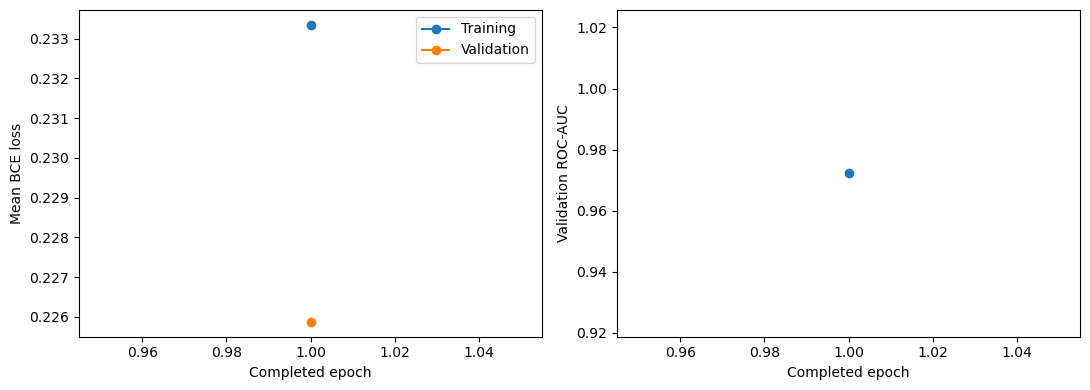

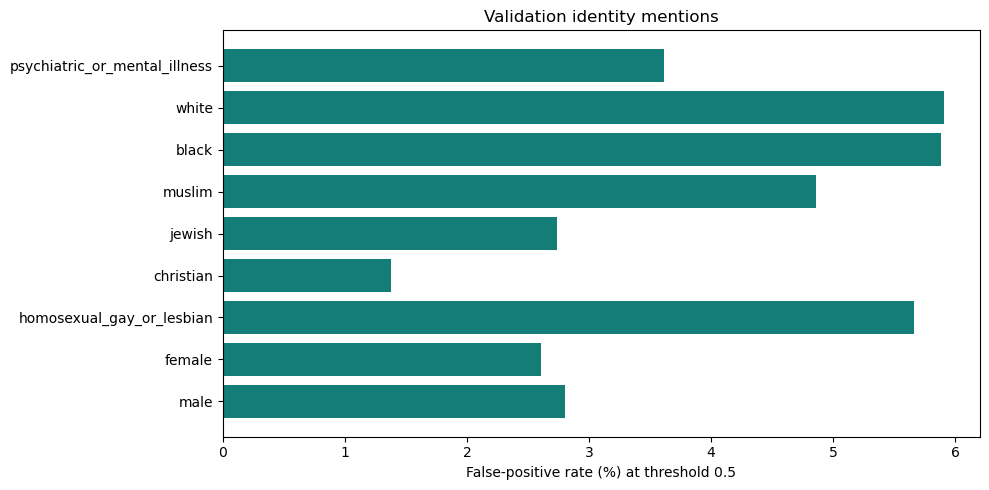

Highest-scoring false positives at 0.5:


,id,comment_text,target,toxic,score
192934,5689081,... what a spoiled BRAT MORON we have as a Pre...,0.400000,0,0.891244
246620,6139782,"thanks Obama, for having your head up your own...",0.239130,0,0.876423
52221,671946,Holy crap! You are amaze! Such fun!,0.304348,0,0.858837
190762,5671088,"Good for you, for standing up to MORONS!",0.492754,0,0.850096
231369,6012718,Moron in chief.,0.385714,0,0.845177


Lowest-scoring false negatives at 0.5:


,id,comment_text,target,toxic,score
75797,866106,I question the spending of gobs and gobs and g...,0.800000,1,0.007461
23434,435223,Two-timer. Cad.,0.500000,1,0.007846
68715,808582,"Talking about cadavers, Conway's husband of ei...",0.500000,1,0.008544
140478,5268328,C-O-W-A-R-D,0.662162,1,0.008847
268986,6320363,"You are correct, in the previous life. If one ...",0.600000,1,0.010014


In [12]:
history = pd.DataFrame(state["validation_history"])
if not history.empty:
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    axes[0].plot(history["epoch"], history["train_loss"], marker="o", label="Training")
    axes[0].plot(history["epoch"], history["validation_loss"], marker="o", label="Validation")
    axes[0].set(xlabel="Completed epoch", ylabel="Mean BCE loss")
    axes[0].legend()
    axes[1].plot(history["epoch"], history["validation_roc_auc"], marker="o")
    axes[1].set(xlabel="Completed epoch", ylabel="Validation ROC-AUC")
    fig.tight_layout()
    fig.savefig(RUN_DIR / "training_curves.png", dpi=160)
    plt.show()

plot_groups = identity_results.loc[identity_results["primary_group"] & identity_results["fpr"].notna()].copy()
if not plot_groups.empty:
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.barh(plot_groups["identity"], 100 * plot_groups["fpr"], color="#147D78")
    ax.set(xlabel="False-positive rate (%) at threshold 0.5", title="Validation identity mentions")
    fig.tight_layout()
    fig.savefig(RUN_DIR / "validation_identity_fpr.png", dpi=160)
    plt.show()

error_examples = validation_df[["id", "comment_text", "target", "toxic"]].copy()
error_examples["score"] = validation_scores
false_positives = error_examples.loc[error_examples["toxic"].eq(0) & error_examples["score"].ge(0.5)]
false_negatives = error_examples.loc[error_examples["toxic"].eq(1) & error_examples["score"].lt(0.5)]
print("Highest-scoring false positives at 0.5:")
display(false_positives.nlargest(5, "score"))
print("Lowest-scoring false negatives at 0.5:")
display(false_negatives.nsmallest(5, "score"))


## Illustrative inference

Hand-written examples illustrate model behavior only. They are not benchmark observations and are excluded from training and evaluation data.


In [13]:
@torch.inference_mode()
def predict_toxicity(comments, threshold=None):
    if isinstance(comments, str):
        comments = [comments]
    if not comments:
        return pd.DataFrame(columns=["comment", "toxicity_score", "threshold", "prediction"])
    if threshold is None:
        threshold = json.loads((RUN_DIR / "selected_threshold.json").read_text())["threshold"]
    if not 0 <= threshold <= 1:
        raise ValueError("Threshold must lie in [0, 1].")
    model.eval()
    scores = []
    for start in range(0, len(comments), CONFIG["eval_batch_size"]):
        inputs = tokenizer(comments[start:start + CONFIG["eval_batch_size"]], padding=True,
                           truncation=True, max_length=CONFIG["max_length"], return_tensors="pt")
        inputs = {key: value.to(DEVICE) for key, value in inputs.items()}
        with amp_context():
            logits = model(**inputs).logits.squeeze(-1)
        scores.extend(torch.sigmoid(logits.float()).cpu().tolist())
    return pd.DataFrame({
        "comment": comments, "toxicity_score": scores, "threshold": threshold,
        "prediction": ["toxic" if score >= threshold else "non-toxic" for score in scores]
    })

display(predict_toxicity([
    "I've hit the Asian flow state.",
    "I am Asian and I love tea.",
    "You're Asian, so your opinion doesn't matter.",
    "Thanks for explaining this."
]))


,comment,toxicity_score,threshold,prediction
0,I've hit the Asian flow state.,0.068912,0.405449,non-toxic
1,I am Asian and I love tea.,0.011158,0.405449,non-toxic
2,"You're Asian, so your opinion doesn't matter.",0.367157,0.405449,non-toxic
3,Thanks for explaining this.,0.003112,0.405449,non-toxic


## Reporting notes

The run configuration, input fingerprints, training log, validation history, predictions, identity tables, and plots form the baseline experiment record. Results should state the number of completed epochs and distinguish validation evidence from final test performance.

## References

Hugging Face BERT documentation: https://huggingface.co/docs/transformers/model_doc/bert

PyTorch automatic mixed precision: https://docs.pytorch.org/docs/stable/amp.html

PyTorch MPS backend: https://docs.pytorch.org/docs/stable/notes/mps.html

Jigsaw dataset: https://www.kaggle.com/competitions/jigsaw-unintended-bias-in-toxicity-classification/data
